# IaCGen with a security gate against IaCGen, IaCGen-MAS, its variant without the Retriever, coding agents and zero-shot (DeepSeek-V4-Flash, CloudFormation)

## Setup

In [1]:
import sys, re, csv, math, json, shutil, subprocess, tempfile, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")
csv.field_size_limit(sys.maxsize)

FINAL = Path("../results"); DATA = Path("../data"); RES = Path("result/final")
FIG = Path("plots/iacgen_gate"); FIG.mkdir(parents=True, exist_ok=True)
OUT = RES
plt.style.use("ggplot"); sns.set_palette("muted")
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 100, "display.max_rows", 200)

GATE = "CFN_RealAWS_IaCGen_DSV4Flash_Security"
PLAIN = "CFN_RealAWS_IaCGen_DSV4Flash"
SYSTEMS = {
    "IaCGen + gate": GATE,
    "IaCGen": PLAIN,
    "IaCGen-MAS without Retriever": "CFN_RealAWS_NoRetrieval_DSV4Flash",
    "IaCGen-MAS": "CFN_RealAWS_DSV4F",
    "OpenCode + Validator": "CFN_RealAWS_OpenCode_DSV4F",
    "OpenCode (AWS CLI)": "CFN_RealAWS_OpencodeAgent_DSV4F",
    "Zero-shot": "CFN_RealAWS_OneShot_DSV4F",
}
ORDER = list(SYSTEMS)
NO_GATE = ["IaCGen"]
LV = [1, 2, 3, 4, 5]
SEV_COLS = ["severity_critical_failed", "severity_high_failed"]

def wilson(k, n, z=1.959964):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)

def holm(pvals):
    p = np.asarray(pvals, float); o = np.argsort(p); m = len(p); adj = np.empty(m)
    adj[o] = np.minimum(1, np.maximum.accumulate(p[o] * (m - np.arange(m))))
    return adj

def newcombe(a, b, c, d):
    n = a + b + c + d; p1, p2 = (a + b) / n, (a + c) / n
    l1, u1 = wilson(a + b, n); l2, u2 = wilson(a + c, n)
    den = math.sqrt(float((a + b) * (c + d) * (a + c) * (b + d)))
    phi = (a * d - b * c) / den if den > 0 else 0.0
    D = p1 - p2
    lo = D - math.sqrt(max(0.0, (p1 - l1) ** 2 - 2 * phi * (p1 - l1) * (u2 - p2) + (u2 - p2) ** 2))
    hi = D + math.sqrt(max(0.0, (u1 - p1) ** 2 - 2 * phi * (u1 - p1) * (p2 - l2) + (p2 - l2) ** 2))
    return D, lo, hi

## Load the results

In [2]:
bench = pd.read_csv(DATA / "cfn_eval_benchmark_real_aws.csv").drop_duplicates("row_number").set_index("row_number")
dcol = "difficulty" if "difficulty" in bench else "difficulty_level"

def severe_by_run(e):
    t = pd.read_csv(RES / f"Trivy_{e}.csv", engine="python").drop_duplicates("run_id")
    t = t[t.total_checks.notna()]
    return t.set_index("run_id").pipe(lambda x: (x[SEV_COLS[0]].fillna(0) + x[SEV_COLS[1]].fillna(0)) > 0)

frames = []
for name, e in SYSTEMS.items():
    r = pd.read_csv(FINAL / e / "results_final.csv", engine="python").drop_duplicates("row_number")
    r["system"] = name; r["exp"] = e
    r["difficulty"] = r.row_number.map(bench[dcol]).astype(int)
    ok = r.validity.eq("valid_pass")
    if "OpencodeAgent" not in e:
        ok &= r.iterations_used <= 15
    r["ok"] = ok
    r["severe"] = r.run_id.map(severe_by_run(e))
    r["deploys"] = r.ok if name in NO_GATE or name == "IaCGen + gate" else np.nan
    r["passed"] = (r.ok & r.severe.eq(False)) if name in NO_GATE else r.ok
    frames.append(r)
runs = pd.concat(frames, ignore_index=True)
runs["system"] = pd.Categorical(runs.system, ORDER, ordered=True)
runs.groupby("system", observed=True).agg(rows=("row_number", "size"), deploys=("deploys", lambda s: s.sum(min_count=1)), passed=("passed", "sum"),
                                          audit_severe_among_passed=("severe", lambda s: int(s[runs.loc[s.index, "passed"]].eq(True).sum())),
                                          invalid=("validity", lambda s: int(s.astype(str).str.startswith("invalid").sum())), max_iterations=("iterations_used", "max"))

,rows,deploys,passed,audit_severe_among_passed,invalid,max_iterations
system,,,,,,
IaCGen + gate,250,216.0,216,1,0,15.0
IaCGen,250,219.0,181,0,3,15.0
IaCGen-MAS without Retriever,250,NaN,234,1,6,15.0
IaCGen-MAS,250,NaN,247,1,1,15.0
OpenCode + Validator,250,NaN,227,3,2,17.0
OpenCode (AWS CLI),250,NaN,214,3,13,1.0
Zero-shot,250,NaN,97,0,6,1.0


## Pass rate

In [3]:
rows = []
for name, g in runs.groupby("system", observed=True, sort=False):
    for crit in ("deploys", "passed"):
        if g[crit].isna().all():
            continue
        p = g[crit].astype(bool); k = int(p.sum()); lo, hi = wilson(k, len(g))
        rows.append(dict(system=name, criterion="deploys" if crit == "deploys" else "deployable and secure", rows=len(g), passed=k, pass_pct=round(100 * k / len(g), 1),
                         ci_lo=round(100 * lo, 1), ci_hi=round(100 * hi, 1), iters_mean_passed=round(g.loc[p, "iterations_used"].mean(), 2), iters_median_passed=g.loc[p, "iterations_used"].median()))
HEAD = pd.DataFrame(rows)
HEAD

,system,criterion,rows,passed,pass_pct,ci_lo,ci_hi,iters_mean_passed,iters_median_passed
0,IaCGen + gate,deploys,250,216,86.4,81.6,90.1,3.34,2.0
1,IaCGen + gate,deployable and secure,250,216,86.4,81.6,90.1,3.34,2.0
2,IaCGen,deploys,250,219,87.6,82.9,91.1,3.36,2.0
3,IaCGen,deployable and secure,250,181,72.4,66.6,77.6,3.31,2.0
4,IaCGen-MAS without Retriever,deployable and secure,250,234,93.6,89.9,96.0,3.37,3.0
5,IaCGen-MAS,deployable and secure,250,247,98.8,96.5,99.6,3.71,3.0
6,OpenCode + Validator,deployable and secure,250,227,90.8,86.6,93.8,2.70,2.0
7,OpenCode (AWS CLI),deployable and secure,250,214,85.6,80.7,89.4,1.00,1.0
8,Zero-shot,deployable and secure,250,97,38.8,33.0,45.0,1.00,1.0


## Pass rate by difficulty level

,system,criterion,L1,L2,L3,L4,L5
0,IaCGen + gate,deploys,88.0,92.0,90.0,78.0,84.0
1,IaCGen + gate,deployable and secure,88.0,92.0,90.0,78.0,84.0
2,IaCGen,deploys,88.0,92.0,80.0,86.0,92.0
3,IaCGen,deployable and secure,76.0,88.0,72.0,60.0,66.0
4,IaCGen-MAS without Retriever,deployable and secure,90.0,94.0,98.0,90.0,96.0
5,IaCGen-MAS,deployable and secure,96.0,100.0,100.0,100.0,98.0
6,OpenCode + Validator,deployable and secure,96.0,94.0,98.0,80.0,86.0
7,OpenCode (AWS CLI),deployable and secure,92.0,92.0,82.0,84.0,78.0
8,Zero-shot,deployable and secure,54.0,56.0,36.0,22.0,26.0


difficulty,1,2,3,4,5
IaCGen + gate,6,4,5,11,8
IaCGen,12,6,14,20,17
IaCGen-MAS without Retriever,5,3,1,5,2
IaCGen-MAS,2,0,0,0,1
OpenCode + Validator,2,3,1,10,7
OpenCode (AWS CLI),4,4,9,8,11
Zero-shot,23,22,32,39,37


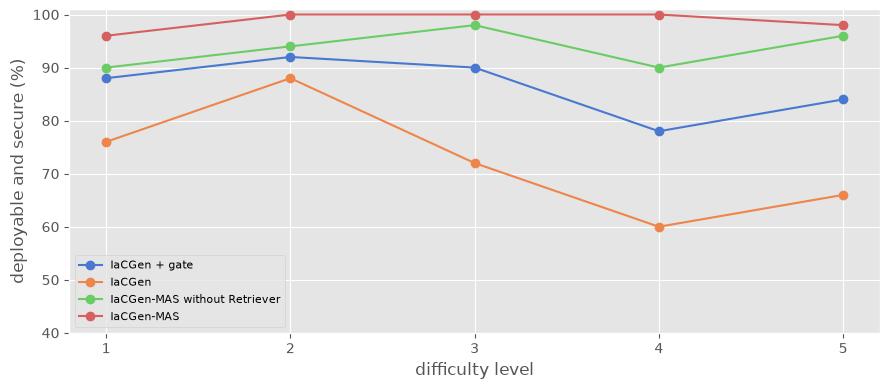

In [4]:
lv = []
for name, g in runs.groupby("system", observed=True, sort=False):
    for crit in ("deploys", "passed"):
        if g[crit].isna().all():
            continue
        s = g[crit].astype(bool).groupby(g.difficulty).mean().mul(100).round(1)
        lv.append(dict(system=name, criterion="deploys" if crit == "deploys" else "deployable and secure", **{f"L{k}": s.get(k) for k in LV}))
LEVEL = pd.DataFrame(lv)
display(LEVEL)
FAILS_LEVEL = pd.concat({n: (~runs[runs.system == n].passed.astype(bool)).groupby(runs[runs.system == n].difficulty).sum() for n in ORDER}, axis=1).T
display(FAILS_LEVEL)
fig, ax = plt.subplots(figsize=(9, 4))
for _, x in LEVEL[LEVEL.system.isin(["IaCGen + gate", "IaCGen", "IaCGen-MAS without Retriever", "IaCGen-MAS"]) & LEVEL.criterion.eq("deployable and secure")].iterrows():
    ax.plot(LV, [x[f"L{k}"] for k in LV], marker="o", label=x.system)
ax.set_xlabel("difficulty level"); ax.set_ylabel("deployable and secure (%)"); ax.set_xticks(LV); ax.set_ylim(40, 101); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "pass_by_level.png", dpi=160); plt.show()

## passItr@n

n,1,2,3,5,10,15,19
"IaCGen + gate, deploys",19.6,44.0,58.4,72.0,84.0,86.4,86.4
"IaCGen + gate, deployable and secure",19.6,44.0,58.4,72.0,84.0,86.4,86.4
"IaCGen, deploys",23.6,44.8,58.4,76.4,83.2,87.6,87.6
"IaCGen, deployable and secure",20.0,37.2,48.8,63.2,68.8,72.4,72.4
"IaCGen-MAS without Retriever, deployable and secure",22.4,45.2,62.0,78.8,90.4,93.6,93.6
"IaCGen-MAS, deployable and secure",19.2,47.6,62.4,80.0,93.2,98.8,98.8
"OpenCode + Validator, deployable and secure",31.6,55.6,70.4,82.0,88.0,90.8,90.8


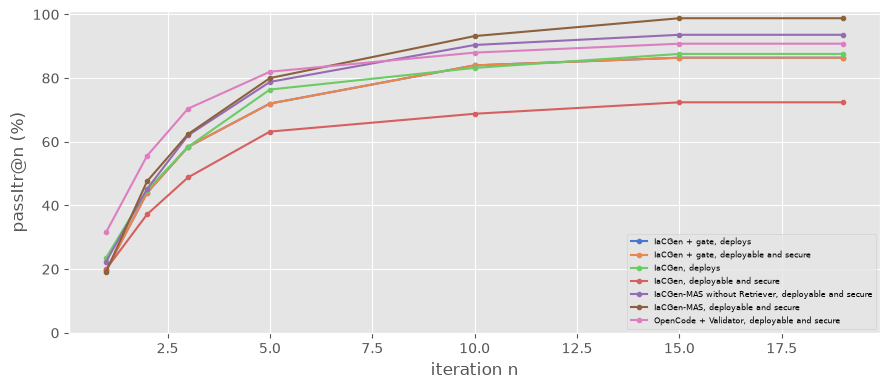

In [5]:
N = [1, 2, 3, 5, 10, 15, 19]
cv = {}
for name, g in runs.groupby("system", observed=True, sort=False):
    if name.startswith("Zero-shot") or name == "OpenCode (AWS CLI)":
        continue
    for crit in ("deploys", "passed"):
        if g[crit].isna().all():
            continue
        ok = g[crit].astype(bool)
        cv[f"{name}, {'deploys' if crit == 'deploys' else 'deployable and secure'}"] = [round(100 * (ok & (g.iterations_used <= n)).mean(), 1) for n in N]
CURVE = pd.DataFrame(cv, index=pd.Index(N, name="n")).T
display(CURVE)
fig, ax = plt.subplots(figsize=(9, 4))
for c, x in CURVE.iterrows():
    ax.plot(N, x.values, marker="o", ms=3, label=c)
ax.set_xlabel("iteration n"); ax.set_ylabel("passItr@n (%)"); ax.set_ylim(0, 101); ax.legend(fontsize=6)
plt.tight_layout(); plt.savefig(FIG / "passitr_curve.png", dpi=160); plt.show()

## Paired comparisons

In [6]:
R = {n: runs[runs.system == n].set_index("row_number") for n in ORDER}
spec = [("IaCGen-MAS", "passed", "IaCGen + gate", "passed"), ("IaCGen + gate", "passed", "IaCGen", "passed"), ("IaCGen", "deploys", "IaCGen + gate", "passed"),
        ("IaCGen-MAS without Retriever", "passed", "IaCGen + gate", "passed"), ("IaCGen-MAS", "passed", "IaCGen-MAS without Retriever", "passed"),
        ("OpenCode + Validator", "passed", "IaCGen + gate", "passed"), ("IaCGen + gate", "passed", "OpenCode (AWS CLI)", "passed"), ("IaCGen + gate", "passed", "Zero-shot", "passed")]
rows = []
for a, ca, b, cb in spec:
    idx = R[a].index.intersection(R[b].index)
    x = R[a].loc[idx, ca].astype(bool).values; y = R[b].loc[idx, cb].astype(bool).values
    both, oa, ob, nei = int((x & y).sum()), int((x & ~y).sum()), int((~x & y).sum()), int((~x & ~y).sum())
    D, lo, hi = newcombe(both, oa, ob, nei)
    rows.append(dict(first=a, first_criterion=ca, second=b, second_criterion=cb, rows=len(idx), first_pass=int(x.sum()), second_pass=int(y.sum()), only_first=oa, only_second=ob,
                     diff_pp=round(100 * D, 1), ci_lo=round(100 * lo, 1), ci_hi=round(100 * hi, 1), p=stats.binomtest(oa, oa + ob, 0.5).pvalue if oa + ob else 1.0))
PAIRS = pd.DataFrame(rows)
PAIRS["p_holm"] = holm(PAIRS.p.values)
PAIRS.replace({"passed": "deployable and secure"})

,first,first_criterion,second,second_criterion,rows,first_pass,second_pass,only_first,only_second,diff_pp,ci_lo,ci_hi,p,p_holm
0,IaCGen-MAS,deployable and secure,IaCGen + gate,deployable and secure,250,247,216,31,0,12.4,8.6,17.0,9.313226e-10,6.519258e-09
1,IaCGen + gate,deployable and secure,IaCGen,deployable and secure,250,216,181,49,14,14.0,8.0,20.0,1.112302e-05,6.673814e-05
2,IaCGen,deploys,IaCGen + gate,deployable and secure,250,219,216,17,14,1.2,-3.3,5.7,7.201001e-01,1.000000e+00
3,IaCGen-MAS without Retriever,deployable and secure,IaCGen + gate,deployable and secure,250,234,216,20,2,7.2,3.7,11.2,1.211166e-04,6.055832e-04
4,IaCGen-MAS,deployable and secure,IaCGen-MAS without Retriever,deployable and secure,250,247,234,14,1,5.2,2.4,8.8,9.765625e-04,3.906250e-03
5,OpenCode + Validator,deployable and secure,IaCGen + gate,deployable and secure,250,227,216,24,13,4.4,-0.4,9.3,9.887175e-02,2.966152e-01
6,IaCGen + gate,deployable and secure,OpenCode (AWS CLI),deployable and secure,250,216,214,25,23,0.8,-4.7,6.3,8.854335e-01,1.000000e+00
7,IaCGen + gate,deployable and secure,Zero-shot,deployable and secure,250,216,97,126,7,47.6,40.4,54.0,2.416903e-29,1.933523e-28


## Decomposing the lead under one criterion

In [7]:
idx = R["IaCGen-MAS"].index.intersection(R["IaCGen + gate"].index).intersection(R["IaCGen-MAS without Retriever"].index)
m_, n_, g_ = [R[k].loc[idx, "passed"].astype(bool).values.astype(int) for k in ("IaCGen-MAS", "IaCGen-MAS without Retriever", "IaCGen + gate")]
rng = np.random.default_rng(0); B = 20000; shares = []
for _ in range(B):
    i = rng.integers(0, len(idx), len(idx))
    t = (m_[i] - g_[i]).sum()
    if t > 0:
        shares.append((m_[i] - n_[i]).sum() / t)
DECOMP = pd.DataFrame([dict(iacgen_gate=int(g_.sum()), mas_no_retriever=int(n_.sum()), mas=int(m_.sum()), lead_over_gate=int((m_ - g_).sum()), by_retriever=int((m_ - n_).sum()), by_rest=int((n_ - g_).sum()),
                            retriever_share_pct=round(100 * (m_ - n_).sum() / (m_ - g_).sum(), 1), boot_ci_lo=round(100 * np.percentile(shares, 2.5), 1), boot_ci_hi=round(100 * np.percentile(shares, 97.5), 1), bootstrap=len(shares))])
plain_secure, plain_deploys = R["IaCGen"].loc[idx, "passed"].astype(bool), R["IaCGen"].loc[idx, "deploys"].astype(bool)
LADDER = pd.DataFrame([dict(step="IaCGen", passed=int(plain_secure.sum())), dict(step="IaCGen + gate", passed=int(g_.sum())), dict(step="IaCGen-MAS without Retriever", passed=int(n_.sum())), dict(step="IaCGen-MAS", passed=int(m_.sum()))])
LADDER["gain"] = LADDER.passed.diff()
LADDER["share_of_lead_pct"] = (100 * LADDER.gain / (LADDER.passed.iloc[-1] - LADDER.passed.iloc[0])).round(1)
display(DECOMP); LADDER

,iacgen_gate,mas_no_retriever,mas,lead_over_gate,by_retriever,by_rest,retriever_share_pct,boot_ci_lo,boot_ci_hi,bootstrap
0,216,234,247,31,13,18,41.9,21.7,63.9,20000


,step,passed,gain,share_of_lead_pct
0,IaCGen,181,NaN,NaN
1,IaCGen + gate,216,35.0,53.0
2,IaCGen-MAS without Retriever,234,18.0,27.3
3,IaCGen-MAS,247,13.0,19.7


## What the gate changes for each scenario

In [8]:
a = R["IaCGen + gate"]; b = R["IaCGen"]
idx = a.index.intersection(b.index)
fx = pd.DataFrame({"difficulty": a.loc[idx, "difficulty"], "gate_pass": a.loc[idx, "passed"].astype(bool), "plain_deploys": b.loc[idx, "deploys"].astype(bool), "plain_severe": b.loc[idx, "severe"].eq(True),
                   "gate_iterations": a.loc[idx, "iterations_used"], "plain_iterations": b.loc[idx, "iterations_used"], "gate_stage": a.loc[idx, "failed_at_stage"]})
fx["plain_outcome"] = np.select([~fx.plain_deploys, fx.plain_severe], ["does not deploy", "deploys, severe finding"], "deploys, secure")
GATE_FX = pd.crosstab(fx.plain_outcome, fx.gate_pass.map({True: "gate passes", False: "gate fails"}), margins=True)
display(GATE_FX)
display(pd.crosstab(fx.loc[~fx.gate_pass, "plain_outcome"], fx.loc[~fx.gate_pass, "gate_stage"].fillna("-"), margins=True))
both = fx[fx.gate_pass & fx.plain_deploys & ~fx.plain_severe]
ITERS_BOTH = dict(rows=len(both), gate_mean=round(both.gate_iterations.mean(), 2), plain_mean=round(both.plain_iterations.mean(), 2), wilcoxon_p=stats.wilcoxon(both.gate_iterations, both.plain_iterations).pvalue if (both.gate_iterations != both.plain_iterations).any() else 1.0)
fixed = fx[fx.gate_pass & fx.plain_deploys & fx.plain_severe]
ITERS_FIXED = dict(rows=len(fixed), gate_mean=round(fixed.gate_iterations.mean(), 2), plain_mean=round(fixed.plain_iterations.mean(), 2))
print("passed by both, previously secure:", ITERS_BOTH); print("previously deployed with a severe finding, now passing:", ITERS_FIXED)
GATE_FX

gate_pass,gate fails,gate passes,All
plain_outcome,,,
"deploys, secure",14,167,181
"deploys, severe finding",3,35,38
does not deploy,17,14,31
All,34,216,250


gate_stage,deployment,security,syntax_validation,yaml_validation,All
plain_outcome,,,,,
"deploys, secure",11,0,3,0,14
"deploys, severe finding",2,0,1,0,3
does not deploy,10,2,4,1,17
All,23,2,8,1,34


passed by both, previously secure: {'rows': 167, 'gate_mean': np.float64(2.93), 'plain_mean': np.float64(3.14), 'wilcoxon_p': np.float64(0.4376144503088808)}
previously deployed with a severe finding, now passing: {'rows': 35, 'gate_mean': np.float64(4.77), 'plain_mean': np.float64(3.11)}


gate_pass,gate fails,gate passes,All
plain_outcome,,,
"deploys, secure",14,167,181
"deploys, severe finding",3,35,38
does not deploy,17,14,31
All,34,216,250


## Why runs stop

In [9]:
STOP = []
for n in ["IaCGen + gate", "IaCGen"]:
    g = R[n]; f = g[~g.ok]
    STOP.append(dict(system=n, failed=len(f), iters_min=f.iterations_used.min(), iters_median=f.iterations_used.median(), iters_max=f.iterations_used.max(), **f.failed_at_stage.fillna("-").value_counts().to_dict()))
STOP = pd.DataFrame(STOP).fillna(0)
display(STOP)
pd.crosstab(R["IaCGen + gate"].loc[~R["IaCGen + gate"].ok, "difficulty"], R["IaCGen + gate"].loc[~R["IaCGen + gate"].ok, "failed_at_stage"], margins=True)

,system,failed,iters_min,iters_median,iters_max,deployment,syntax_validation,security,yaml_validation
0,IaCGen + gate,34,15.0,15.0,15.0,23,8,2.0,1
1,IaCGen,31,15.0,15.0,15.0,18,12,0.0,1


failed_at_stage,deployment,security,syntax_validation,yaml_validation,All
difficulty,,,,,
1,6,0,0,0,6
2,3,0,1,0,4
3,3,0,2,0,5
4,6,2,3,0,11
5,5,0,2,1,8
All,23,2,8,1,34


## Repair turns and security findings

In [10]:
RANK = {"yaml_validation": 0, "syntax_validation": 1, "security": 2, "deployment": 3}
def turn_table(eh, res):
    e = eh.copy(); e["row_number"] = e.row_number.astype(int)
    per = e.sort_values(["row_number", "iteration_number"]).groupby(["row_number", "iteration_number"]).agg(stage=("error_stage", "first"), level=("next_feedback_level", "first")).reset_index()
    out = []
    for rn, g in per.groupby("row_number"):
        it = dict(zip(g.iteration_number, g.stage)); ok = bool(res.loc[rn, "ok"]) if rn in res.index else False
        last = max(res.loc[rn, "iterations_used"], max(it)) if rn in res.index else max(it)
        for _, x in g.iterrows():
            k = x.iteration_number
            if k >= last and not ok:
                continue
            nxt = it.get(k + 1); nr = RANK[nxt] if nxt is not None else 9
            out.append(dict(row_number=rn, iteration=k, stage=x.stage, feedback=x.level, next_stage=nxt if nxt is not None else "pass", fixed=nr > RANK[x.stage], check_not_rerun=nr < RANK[x.stage]))
    return pd.DataFrame(out)

def episodes(eh, res):
    e = eh.copy(); e["row_number"] = e.row_number.astype(int)
    per = e.sort_values(["row_number", "iteration_number"]).groupby(["row_number", "iteration_number"]).error_stage.first()
    out = []
    for rn, g in per.groupby(level=0):
        st = {k[1]: v for k, v in g.items()}
        ok = bool(res.loc[rn, "ok"]) if rn in res.index else False
        last = int(res.loc[rn, "iterations_used"]) if rn in res.index else max(st)
        rank = {k: RANK[st[k]] if k in st else 9 for k in range(1, max(last, max(st)) + 1)}
        for cls, r_ in RANK.items():
            k = next((x for x in sorted(st) if st[x] == cls), None)
            while k is not None:
                j = next((x for x in sorted(rank) if x > k and rank[x] > r_), None)
                out.append(dict(row_number=rn, cls=cls, resolved=j is not None, turns=(j - k) if j is not None else np.nan))
                k = next((x for x in sorted(st) if j is not None and x > j and st[x] == cls), None)
    return pd.DataFrame(out)

EH = {n: pd.read_csv(FINAL / SYSTEMS[n] / "error_history.csv", low_memory=False) for n in ["IaCGen + gate", "IaCGen"]}
T = {n: turn_table(EH[n], R[n]) for n in EH}
FIX = pd.concat({n: T[n].groupby("stage").agg(turns=("fixed", "size"), fixed=("fixed", "sum"), check_not_rerun=("check_not_rerun", "sum")).assign(fix_rate=lambda d: (100 * d.fixed / d.turns).round(1)) for n in T}, names=["system"])
display(FIX)
EPISODES = pd.concat({n: episodes(EH[n], R[n]).groupby("cls").agg(scenarios=("row_number", "nunique"), episodes=("resolved", "size"), resolved_pct=("resolved", lambda s: round(100 * s.mean(), 1)),
                                                                  one_turn_pct=("turns", lambda s: round(100 * (s == 1).sum() / len(s), 1)), mean_turns_resolved=("turns", lambda s: round(s.mean(), 2))) for n in EH}, names=["system"])
display(EPISODES)
TRANS = pd.crosstab(T["IaCGen + gate"].stage, T["IaCGen + gate"].next_stage, margins=True)
display(TRANS)
sec = EH["IaCGen + gate"]; sec = sec[sec.error_stage == "security"].copy()
sec["rule"] = sec.error_message.fillna("").str.findall(r"AWS-\d{4}")
RULES = sec.explode("rule").dropna(subset=["rule"]).drop_duplicates(["row_number", "iteration_number", "rule"]).groupby("rule").row_number.agg(iterations="size", scenarios="nunique").sort_values("scenarios", ascending=False)
RULES.head(12)

turns  fixed  check_not_rerun  fix_rate
system        stage                                                     
IaCGen + gate deployment           442     82              113      18.6
              security              93     58               17      62.4
              syntax_validation    360    261                5      72.5
              yaml_validation       42     24                0      57.1
IaCGen        deployment           427     78              110      18.3
              syntax_validation    463    232               14      50.1
              yaml_validation       71     47                0      66.2

scenarios  episodes  resolved_pct  one_turn_pct  mean_turns_resolved
system        cls                                                                                    
IaCGen + gate deployment               128       137          81.0          32.8                 2.71
              security                  59        72          97.2          66.7                 1.39
              syntax_validation        162       271          97.0          81.5                 1.28
              yaml_validation           21        25          96.0          80.0                 1.17
IaCGen        deployment               116       121          80.2          29.8                 3.18
              syntax_validation        170       254          94.9          65.4                 1.45
              yaml_validation           37        48          95.8          75.0                 1.50

next_stage,deployment,pass,security,syntax_validation,yaml_validation,All
stage,,,,,,
deployment,247,82,12,99,2,442
security,30,28,18,17,0,93
syntax_validation,141,80,40,94,5,360
yaml_validation,3,5,2,14,18,42
All,421,195,72,224,25,937


,iterations,scenarios
rule,,
AWS-0164,34,26
AWS-0132,13,12
AWS-0104,24,9
AWS-0095,8,8
AWS-0345,8,7
AWS-0067,4,4
AWS-0136,3,3
AWS-0107,3,3
AWS-0093,2,2


## Errors of the failed runs

In [11]:
def category(stage, s):
    s = str(s)
    if stage == "security":
        return "security: finding not repaired"
    if stage == "yaml_validation":
        return "syntax: yaml"
    if stage == "syntax_validation":
        if re.search(r"Additional properties|is a required property", s):
            return "schema: property missing or not allowed"
        if re.search(r"dependency already enforced|not one of|enum", s):
            return "schema: lint rule on value or dependency"
        return "schema or syntax: other"
    if re.search(r"Validation failed with \d+ error|FAILED\] from custom resource", s):
        return "deployment: no actionable message"
    if re.search(r"not authorized|AccessDenied|can't create new", s):
        return "deployment: permission or account"
    if re.search(r"Parameters: \[|must have values|No value", s):
        return "deployment: parameter without value"
    return "deployment: provider rejected the configuration"
FC = []
for n in EH:
    e = EH[n].sort_values(["row_number", "iteration_number"]).groupby("row_number").tail(1).set_index("row_number")
    f = R[n][~R[n].ok]
    for rn, x in f.iterrows():
        FC.append(dict(system=n, row_number=rn, difficulty=x.difficulty, stage=x.failed_at_stage, category=category(x.failed_at_stage, e.error_message.get(rn, "")), last_error=str(e.error_message.get(rn, ""))[:140]))
FC = pd.DataFrame(FC)
FAIL_CAT = FC.groupby(["system", "category"]).agg(rows=("row_number", "size"), row_numbers=("row_number", lambda s: ", ".join(map(str, sorted(s))))).reset_index()
FAIL_CAT

,system,category,rows,row_numbers
0,IaCGen,deployment: no actionable message,5,"20, 37, 114, 121, 175"
1,IaCGen,deployment: parameter without value,1,230
2,IaCGen,deployment: permission or account,4,"26, 85, 87, 257"
3,IaCGen,deployment: provider rejected the configuration,8,"2, 6, 58, 90, 103, 125, 174, 197"
4,IaCGen,schema or syntax: other,2,"8, 263"
5,IaCGen,schema: lint rule on value or dependency,3,"77, 156, 229"
6,IaCGen,schema: property missing or not allowed,7,"17, 72, 91, 127, 150, 152, 242"
7,IaCGen,syntax: yaml,1,81
8,IaCGen + gate,deployment: no actionable message,11,"6, 13, 20, 37, 46, 77, 114, 175, 213, 236, 250"
9,IaCGen + gate,deployment: parameter without value,1,191


## Sensitivity to cfn-lint warnings

In [12]:
CFN_LINT = shutil.which("cfn-lint")
assert CFN_LINT, "cfn-lint not on PATH"
def lint_levels(template):
    with tempfile.NamedTemporaryFile("w", suffix=".yaml", delete=False) as fh:
        fh.write(template); path = fh.name
    p = subprocess.run([CFN_LINT, "--format", "json", path], capture_output=True, text=True)
    Path(path).unlink(missing_ok=True)
    assert not (p.returncode & 1) and p.stdout.strip(), (p.returncode, p.stderr[:200])
    items = json.loads(p.stdout)
    return dict(errors=sum(i["Level"] == "Error" for i in items), warnings=sum(i["Level"] == "Warning" for i in items),
                rules=" ".join(sorted({i["Rule"]["Id"] for i in items})))
canary = lint_levels("AWSTemplateFormatVersion: '2010-09-09'\nResources:\n  B:\n    Type: AWS::S3::Bucket\n    Properties:\n      NotAProperty: 1\n")
assert canary["errors"] >= 1, canary
SENS = []
for n in ["IaCGen + gate", "IaCGen"]:
    f = R[n][(~R[n].ok) & R[n].failed_at_stage.eq("syntax_validation")]
    for rn, x in f.iterrows():
        SENS.append(dict(system=n, row_number=rn, difficulty=x.difficulty, **lint_levels(str(x.final_template))))
SENS = pd.DataFrame(SENS)
display(SENS)
LINT_SENS = SENS.assign(warning_only=SENS.errors.eq(0)).groupby("system").agg(failed_at_lint=("row_number", "size"), warning_only=("warning_only", "sum")).reset_index()
LINT_SENS["passed"] = LINT_SENS.system.map(lambda n: int(R[n].passed.astype(bool).sum()))
LINT_SENS["upper_bound_pct"] = (100 * (LINT_SENS.passed + LINT_SENS.warning_only) / 250).round(1)
print(subprocess.run([CFN_LINT, "--version"], capture_output=True, text=True).stdout.strip())
LINT_SENS

,system,row_number,difficulty,errors,warnings,rules
0,IaCGen + gate,74,3,0,2,W3005
1,IaCGen + gate,85,3,0,1,W3005
2,IaCGen + gate,120,4,1,0,E3002
3,IaCGen + gate,123,4,2,0,E3002 E3003
4,IaCGen + gate,142,4,0,2,W1020
5,IaCGen + gate,174,5,2,3,E2533 W3005
6,IaCGen + gate,197,5,0,6,W3005
7,IaCGen + gate,263,2,0,1,W3005
8,IaCGen,8,1,1,0,E3012
9,IaCGen,17,1,6,0,E3003


cfn-lint 1.48.1


,system,failed_at_lint,warning_only,passed,upper_bound_pct
0,IaCGen,12,2,181,73.2
1,IaCGen + gate,8,5,216,88.4


## Security audit of the final templates

In [13]:
sv = []
for name, e in SYSTEMS.items():
    t = pd.read_csv(RES / f"Trivy_{e}.csv", engine="python").drop_duplicates("run_id")
    t = t[t.run_id.isin(runs.loc[runs.exp == e, "run_id"].dropna()) & t.total_checks.notna()]
    row = dict(system=name, templates=len(t), policy_pass_pct=100 * (t.total_passed / t.total_checks.replace(0, np.nan)).mean(), clean_pct=100 * (t.total_failed == 0).mean(),
               with_critical_or_high_pct=100 * ((t[SEV_COLS[0]].fillna(0) + t[SEV_COLS[1]].fillna(0)) > 0).mean())
    for s in ("critical", "high", "medium", "low"):
        row[f"{s}_pass_pct"] = 100 * t[f"severity_{s}_passed"].sum() / t[f"severity_{s}_eval"].sum()
    sv.append(row)
SEC = pd.DataFrame(sv).round(1)
SEC

,system,templates,policy_pass_pct,clean_pct,with_critical_or_high_pct,critical_pass_pct,high_pass_pct,medium_pass_pct,low_pass_pct
0,IaCGen + gate,250,95.8,42.0,2.4,99.2,99.6,96.7,83.1
1,IaCGen,250,94.7,41.2,18.8,96.9,94.3,96.9,82.7
2,IaCGen-MAS without Retriever,250,94.8,37.2,1.6,100.0,99.5,96.0,78.3
3,IaCGen-MAS,250,95.4,40.8,0.8,100.0,99.9,95.8,81.9
4,OpenCode + Validator,250,96.2,44.8,1.2,100.0,99.7,96.7,85.5
5,OpenCode (AWS CLI),250,96.0,43.6,2.4,100.0,98.9,96.8,84.4
6,Zero-shot,250,95.8,49.2,16.4,97.4,95.9,97.4,86.8


## Resources of the final templates

In [14]:
cv = []
for name, e in SYSTEMS.items():
    c = pd.read_csv(RES / f"Coverage_{e}.csv", engine="python")
    c = c[c.row_number.isin(runs.loc[(runs.exp == e) & runs.run_id.notna(), "row_number"])].drop_duplicates("row_number")
    cv.append(dict(system=name, templates=len(c), extra_mean=c.extra_resources.mean(), missing_mean=c.missing_resources.mean(), recall_pct=c.coverage_pct.mean(), precision_pct=c.accuracy_pct.mean()))
COVERAGE = pd.DataFrame(cv).round(2)
display(COVERAGE)
ca = pd.read_csv(RES / f"Coverage_{GATE}.csv", engine="python").drop_duplicates("row_number").set_index("row_number")
cb = pd.read_csv(RES / f"Coverage_{PLAIN}.csv", engine="python").drop_duplicates("row_number").set_index("row_number")
sel = fx[fx.gate_pass & fx.plain_deploys].index
sel = sel[sel.isin(ca.index) & sel.isin(cb.index)]
EXTRA_TEST = dict(rows=len(sel), gate_extra=round(ca.loc[sel, "extra_resources"].mean(), 2), plain_extra=round(cb.loc[sel, "extra_resources"].mean(), 2), wilcoxon_p=stats.wilcoxon(ca.loc[sel, "extra_resources"], cb.loc[sel, "extra_resources"]).pvalue,
                  gate_precision=round(ca.loc[sel, "accuracy_pct"].mean(), 1), plain_precision=round(cb.loc[sel, "accuracy_pct"].mean(), 1))
fixed_sel = fx[fx.gate_pass & fx.plain_deploys & fx.plain_severe].index.intersection(ca.index).intersection(cb.index)
EXTRA_FIXED = dict(rows=len(fixed_sel), gate_extra=round(ca.loc[fixed_sel, "extra_resources"].mean(), 2), plain_extra=round(cb.loc[fixed_sel, "extra_resources"].mean(), 2))
print(EXTRA_TEST); print(EXTRA_FIXED)

,system,templates,extra_mean,missing_mean,recall_pct,precision_pct
0,IaCGen + gate,250,2.12,1.47,86.01,83.15
1,IaCGen,250,1.74,1.54,85.38,87.12
2,IaCGen-MAS without Retriever,250,2.92,1.35,86.51,79.48
3,IaCGen-MAS,250,2.42,1.42,86.02,81.34
4,OpenCode + Validator,250,2.13,1.46,86.34,84.69
5,OpenCode (AWS CLI),250,2.22,1.38,88.11,84.22
6,Zero-shot,250,1.48,1.82,83.11,84.65


{'rows': 202, 'gate_extra': np.float64(1.54), 'plain_extra': np.float64(1.13), 'wilcoxon_p': np.float64(0.016982118968360452), 'gate_precision': np.float64(87.2), 'plain_precision': np.float64(90.5)}
{'rows': 35, 'gate_extra': np.float64(1.89), 'plain_extra': np.float64(1.03)}


## Summary tables

In [15]:
P = "IaCGen_Gate_"
for name, df in {"pass": HEAD, "pass_by_level": LEVEL, "failures_by_level": FAILS_LEVEL.reset_index(names="system"), "passitr": CURVE.reset_index(names="system"), "paired": PAIRS, "decomposition": DECOMP, "ladder": LADDER,
                 "gate_effect": GATE_FX.reset_index(), "stop": STOP, "fix_rate": FIX.reset_index(), "episodes": EPISODES.reset_index(), "transitions": TRANS.reset_index(), "security_rules": RULES.reset_index(), 
                 "failures": FAIL_CAT, "lint_sensitivity": LINT_SENS, "security": SEC, "resources": COVERAGE}.items():
    df.to_csv(OUT / f"{P}{name}.csv", index=False)
pd.DataFrame([dict(item="iterations_both_secure", **ITERS_BOTH), dict(item="iterations_repaired", **ITERS_FIXED), dict(item="extra_resources_deployed_in_both", **EXTRA_TEST), dict(item="extra_resources_repaired", **EXTRA_FIXED)]).to_csv(OUT / f"{P}numbers.csv", index=False)
HEAD

,system,criterion,rows,passed,pass_pct,ci_lo,ci_hi,iters_mean_passed,iters_median_passed
0,IaCGen + gate,deploys,250,216,86.4,81.6,90.1,3.34,2.0
1,IaCGen + gate,deployable and secure,250,216,86.4,81.6,90.1,3.34,2.0
2,IaCGen,deploys,250,219,87.6,82.9,91.1,3.36,2.0
3,IaCGen,deployable and secure,250,181,72.4,66.6,77.6,3.31,2.0
4,IaCGen-MAS without Retriever,deployable and secure,250,234,93.6,89.9,96.0,3.37,3.0
5,IaCGen-MAS,deployable and secure,250,247,98.8,96.5,99.6,3.71,3.0
6,OpenCode + Validator,deployable and secure,250,227,90.8,86.6,93.8,2.70,2.0
7,OpenCode (AWS CLI),deployable and secure,250,214,85.6,80.7,89.4,1.00,1.0
8,Zero-shot,deployable and secure,250,97,38.8,33.0,45.0,1.00,1.0
